<a href="https://colab.research.google.com/github/240215-alt/AI-ML/blob/main/Simple_LR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rsadiq/salary")

print("Path to dataset files:", path)

100%|██████████| 392/392 [00:00<00:00, 730kB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/rsadiq/salary/versions/1


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [ ]:
df = pd.read_csv(os.path.join(path, "Salary.csv"))     # Replace with your file name
print(df.head())
print(df.info())

   YearsExperience  Salary
0              1.1   39343
1              1.3   46205
2              1.5   37731
3              2.0   43525
4              2.2   39891
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  35 non-null     float64
 1   Salary           35 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 692.0 bytes
None


In [ ]:
import os

print(path)
print(os.listdir(path))

/root/.cache/kagglehub/datasets/rsadiq/salary/versions/1
['Salary.csv']


In [ ]:
X = df[['YearsExperience']]
y = df['Salary']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test)


In [ ]:
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

print(f"Regression Equation:")
print(f"Salary = {model.intercept_:.2f} + ({model.coef_[0]:.2f} × YearsExperience)")

Slope: 8578.767476685925
Intercept: 29078.626034406887
Regression Equation:
Salary = 29078.63 + (8578.77 × YearsExperience)


In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE : 6692.364094497284
MSE : 55761791.306260146
RMSE: 7467.381824057221
R² Score: 0.8914234140042779


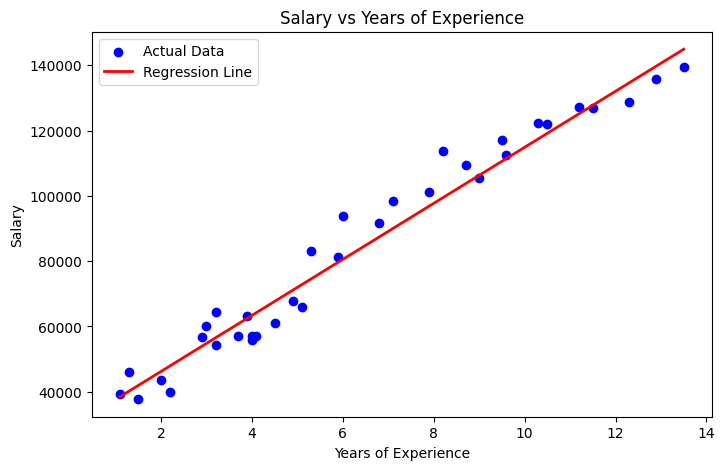

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(X, y, color="blue", label="Actual Data")
plt.plot(X, model.predict(X), color="red", linewidth=2, label="Regression Line")

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Salary vs Years of Experience")
plt.legend()
plt.show()

In [ ]:
years = [[7.5]]

predicted_salary = model.predict(years)

print("Predicted Salary:", predicted_salary[0])

Predicted Salary: 93419.38210955133


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
